# Проект "Рынок стартапов"

## Введение

Финансовая компания рассматривает возможность выхода на рынок венчурных инвестиций — покупку и развитие перспективных стартапов. Чтобы принять взвешенное решение, необходимо понять, как устроено финансирование стартапов: какие суммы и в каких формах привлекают компании, как часто эти вложения окупаются, и какие отрасли и типы финансирования демонстрируют наибольший потенциал.

**Цель проекта** — на основе исторических данных о компаниях, раундах и типах привлечённого финансирования, а также статистики по возвратам средств, исследовать динамику и структуру рынка стартапов и подготовить рекомендации по инвестиционной стратегии.

**В работе используются два датасета:**
- `cb_investments` — сведения о компаниях, объемах и типах привлеченного финансирования;
- `cb_returns` — статистика по возвратам средств инвесторам в разбивке по годам и типам финансирования.

Датасет получен из базы данных стартапов.

Название основного датасета — `cb_investments.zip`. Внутри архива один файл — `cb_investments.csv`.

Описание данных:
* `name` — название компании.
* `homepage_url` — ссылка на сайт компании.
* `category_list` — категории, в которых работает компания. Указываются через `|`.
* `market` — основной рынок или отрасль компании.
* `funding_total_usd` — общий объём привлечённых инвестиций в долларах США.
* `status` — текущий статус компании, например `operating`, `closed` и так далее.
* `country_code` — код страны, например USA.
* `state_code` — код штата или региона, например, CA.
* `region` — регион, например, SF Bay Area.
* `city` — город, в котором расположена компания.
* `funding_rounds` — общее число раундов финансирования.
* `participants` — число участников в раундах финансирования.
* `founded_at` — дата основания компании.
* `founded_month` — месяц основания в формате `YYYY-MM`.
* `founded_quarter` — квартал основания в формате `YYYY-QN`.
* `founded_year` — год основания.
* `first_funding_at` — дата первого финансирования.
* `mid_funding_at` — дата среднего по времени раунда финансирования.
* `last_funding_at` — дата последнего финансирования.
* `seed` — сумма инвестиций на посевной стадии.
* `venture` — сумма венчурных инвестиций.
* `equity_crowdfunding` — сумма, привлечённая через долевой краудфандинг.
* `undisclosed` — сумма финансирования нераскрытого типа.
* `convertible_note` — сумма инвестиций через конвертируемые займы.
* `debt_financing` — сумма долгового финансирования.
* `angel` — сумма инвестиций от бизнес-ангелов.
* `grant` — сумма полученных грантов.
* `private_equity` — сумма инвестиций в виде прямых (частных) вложений.
* `post_ipo_equity` — сумма финансирования после IPO.
* `post_ipo_debt` — сумма долгового финансирования после IPO.
* `secondary_market` — сумма сделок на вторичном рынке.
* `product_crowdfunding` — сумма, привлечённая через продуктовый краудфандинг.
* `round_A` — `round_H` — сумма инвестиций в соответствующем раунде.

Название дополнительного датасета — `cb_returns.csv`. Он содержит суммы возвратов по типам финансирования в миллионах долларов по годам.

Описание данных:
* `year` — год возврата средств.
* `seed` — сумма возвратов от посевных инвестиций.
* `venture` — сумма возвратов от венчурных инвестиций.
* `equity_crowdfunding` — сумма, возвращённая по долевому краудфандингу.
* `undisclosed` — сумма возвратов нераскрытого типа.
* `convertible_note` — сумма возвратов через конвертируемые займы.
* `debt_financing` — сумма возвратов от долгового финансирования.
* `angel` — сумма возвратов бизнес-ангелам.
* `grant` — сумма возвратов по грантам.
* `private_equity` — сумма возвратов прямых (частных) вложений.
* `post_ipo_equity` — сумма возвратов от IPO.
* `post_ipo_debt` — сумма возвратов от долгового IPO.
* `secondary_market` — сумма возвратов от сделок на вторичном рынке.
* `product_crowdfunding` — сумма возвратов по продуктовому краудфандингу.

**План работы:**
1. Знакомство с данными: загрузка и предобработка
2. Инжиниринг признаков: группы по срокам финансирования, классификация сегментов рынка.
3. Анализ выбросов, определение границ периода исследования, сравнение типов финансирования.
4. Анализ динамики: раунды и объемы инвестиций по годам, устойчивость возвратов средств.
5. Итоговые выводы и рекомендации по инвестированию, актуальные для 2015 года.

## Загрузка данных и знакомство с ними

### Загрузка библиотек и датафреймов

In [1]:
# Устанавливаем библиотеку phik
!pip install phik -U   

In [2]:
# Импортируем библиотеки для анализа данных
import pandas as pd
import numpy as np

# Загружаем библиотеки для визуализации данных
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
# Выгружаем данные в переменную investments_df
df_inv = pd.read_csv("https://code.s3.yandex.net/datasets/cb_investments.zip", sep=';', low_memory=False)

In [4]:
# Запоминаем исходное количество строк — понадобится, чтобы оценить
# долю данных, отброшенных в ходе предобработки
rows_raw = len(df_inv)

In [5]:
# Выгружаем данные в переменную returns_df
df_ret = pd.read_csv("https://code.s3.yandex.net/datasets/cb_returns.csv")

### Обзор общей информации

Познакомимся с данными датасета `df_investments` — выведем первые строки методом head(), а информацию о датафрейме методом info():

In [6]:
# Выводим первые строки датафрейма
df_inv.head()

,name,homepage_url,category_list,market,funding_total_usd,status,country_code,state_code,region,city,...,secondary_market,product_crowdfunding,round_A,round_B,round_C,round_D,round_E,round_F,round_G,round_H
0,Harvard University,http://harvard.edu,|Education|,Education,"9,00,00,000",operating,USA,MA,Boston,Cambridge,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,University of New Brunswick,http://www.unb.ca,NaN,NaN,"20,00,000",operating,NaN,NaN,NaN,NaN,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,DuPont,http://www.dupont.com,|Business Services|Agriculture|Automotive|Inve...,Business Services,"90,00,000",operating,USA,DE,"Wilmington, Delaware",Wilmington,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,University of Michigan,http://www.umich.edu/,|Education|,Education,"77,00,000",operating,USA,MI,Detroit,Ann Arbor,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,Case Western Reserve University,http://www.case.edu,|Education|,Education,"5,40,000",operating,USA,OH,Cleveland,Cleveland,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [7]:
# Выводим информацию о датафрейме
df_inv.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 54294 entries, 0 to 54293
Data columns (total 40 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   name                  49437 non-null  object 
 1   homepage_url          45989 non-null  object 
 2   category_list         45477 non-null  object 
 3    market               45477 non-null  object 
 4    funding_total_usd    49438 non-null  object 
 5   status                48124 non-null  object 
 6   country_code          44165 non-null  object 
 7   state_code            30161 non-null  object 
 8   region                44165 non-null  object 
 9   city                  43322 non-null  object 
 10  funding_rounds        49438 non-null  float64
 11  participants          30473 non-null  float64
 12  founded_at            38554 non-null  object 
 13  founded_month         38482 non-null  object 
 14  founded_quarter       38482 non-null  object 
 15  founded_year       

Датасет `df_investments` содержит 54294 строки и 40 столбцов. 
После первичного анализа данных можно сделать следующие выводы:

- Часть строк скорее всего полностью пусты
- У столбцов `market` и `funding_total_usd` есть лишний пробел в начале названия, названия остальных столбцов имеют подходящий вид
- Для целей проекта понадобятся не все столбцы, а только лишь следующие: `name`, `market`, `funding_total_usd`, `funding_rounds`, `first_funding_at`, `mid_funding_at`, `last_funding_at`, а также столбцы с типами финансирования (с 19 по 31)
- Необходимо поменять типы данных в столбцах: `market` на category, `funding_total_usd` на float, `first_funding_at`, `mid_funding_at`, `last_funding_at` на timestamp

Теперь познакомимся с данными датасета `df_returns`

In [8]:
# Выводим первые строки датафрейма
df_ret.head()

,year,seed,venture,equity_crowdfunding,undisclosed,convertible_note,debt_financing,angel,grant,private_equity,post_ipo_equity,post_ipo_debt,secondary_market,product_crowdfunding
0,2000,16.70,55.40,0.0,78.21,0.00,8.66,6.43,0.0,0.00,0.94,0.0,0.20,0.0
1,2001,2.88,23.49,0.0,21.50,0.01,4.49,1.18,0.0,0.00,0.46,0.0,0.46,0.0
2,2002,6.59,209.42,0.0,25.77,0.02,3.42,3.41,0.0,1.51,0.34,0.0,0.06,0.0
3,2003,7.74,233.86,0.0,9.40,0.01,1.09,3.41,0.0,1.62,2.11,0.0,0.08,0.0
4,2004,9.93,555.90,0.0,33.19,0.01,13.55,9.18,0.0,2.19,3.38,0.0,0.55,0.0


In [9]:
# Выводим информацию о датафрейме
df_ret.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15 entries, 0 to 14
Data columns (total 14 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   year                  15 non-null     int64  
 1   seed                  15 non-null     float64
 2   venture               15 non-null     float64
 3   equity_crowdfunding   15 non-null     float64
 4   undisclosed           15 non-null     float64
 5   convertible_note      15 non-null     float64
 6   debt_financing        15 non-null     float64
 7   angel                 15 non-null     float64
 8   grant                 15 non-null     float64
 9   private_equity        15 non-null     float64
 10  post_ipo_equity       15 non-null     float64
 11  post_ipo_debt         15 non-null     float64
 12  secondary_market      15 non-null     float64
 13  product_crowdfunding  15 non-null     float64
dtypes: float64(13), int64(1)
memory usage: 1.8 KB


После знакомства с данными `df_returns` можно сделать следующие выводы:

- Датасет небольшой: строк столько, сколько лет охватывает статистика по возвратам, столбцов — 14 (`year` и 13 типов финансирования);
- Названия столбцов имеют подходящий вид и совпадают по смыслу со столбцами типов финансирования в `df_investments`, что понадобится при сопоставлении данных;
- Столбец `year` нужно сделать индексом датафрейма;
- Пропусков в столбцах, судя по выводу `info()`, либо нет, либо они незначительны — это стоит перепроверить в ходе предобработки.

### Предобработка данных

In [10]:
# Удаляем пробелы в начале названий столбцов
df_inv.columns = df_inv.columns.str.strip()

In [11]:
# Убираем дубликаты в столбце market
df_inv['market'] = df_inv['market'].str.strip()

In [12]:
# Пропуски в текстовых столбцах, которые используются в проекте, заполняем заглушками
df_inv['name'] = df_inv['name'].fillna('unknown')
df_inv['market'] = df_inv['market'].fillna('unknown')

In [13]:
# Удаляем все запятые и пробелы, приводим к int, затем к float
df_inv['funding_total_usd'] = (
    df_inv['funding_total_usd']
    .str.replace(',', '', regex=False)
    .str.strip()
    .apply(pd.to_numeric, errors='coerce')
    .astype('float')
)

In [14]:
# Приводим столбцы с датами к нужному формату
df_inv['first_funding_at'] = pd.to_datetime(df_inv['first_funding_at'], errors='coerce')
df_inv['mid_funding_at'] = pd.to_datetime(df_inv['mid_funding_at'], errors='coerce')
df_inv['last_funding_at'] = pd.to_datetime(df_inv['last_funding_at'], errors='coerce')

In [15]:
# Делаем столбец year индексом всего датасета
df_ret = df_ret.set_index('year')

In [16]:
# Удаляем полные дубликаты
df_inv = df_inv.drop_duplicates(keep='first')

In [17]:
# Убираем строки, которые не несут никакой информации, — полностью пустые записи
df_inv = df_inv.dropna(how='all')

In [18]:
# Оставляем только строки с валидным положительным финансированием
df_inv = df_inv[df_inv['funding_total_usd'].notna()]

In [19]:
# Вычисляем разницу в днях и делим пополам
delta = (df_inv['last_funding_at'] - df_inv['first_funding_at']) / 2

# Получаем предполагаемую дату середины
mid_guess = df_inv['first_funding_at'] + delta

# Заполните пропуски в значениях mid_funding_at
df_inv['mid_funding_at'] = df_inv['mid_funding_at'].fillna(mid_guess)

In [20]:
# Оцениваем размер оставшихся пропусков в столбце
missing_count = df_inv['mid_funding_at'].isna().sum()
total_count = len(df_inv)
missing_ratio = missing_count / total_count if total_count > 0 else 0

print(f"Пропусков в mid_funding_at: {missing_count}")
print(f"Всего строк: {total_count}")
print(f"Доля пропусков: {missing_ratio:.4f} ({missing_ratio*100:.2f}%)")


Пропусков в mid_funding_at: 1
Всего строк: 40907
Доля пропусков: 0.0000 (0.00%)


In [21]:
# Считаем, какая доля исходных строк была отброшена в ходе предобработки
rows_after = len(df_inv)
dropped_share = 1 - rows_after / rows_raw

print(f"Строк до предобработки: {rows_raw}")
print(f"Строк после предобработки: {rows_after}")
print(f"Доля отброшенных строк: {dropped_share:.1%}")

Строк до предобработки: 54294
Строк после предобработки: 40907
Доля отброшенных строк: 24.7%


**Выводы**

- Убраны лишние пробелы в названиях столбцов
- Столбец `funding_total_usd` переведён в числовой тип, даты — в тип `datetime`
- Индексом `cb_returns` стал год
- Удалены полные дубликаты, полностью пустые строки и записи без данных об объеме финансирования.
- Пропуски в `mid_funding_at` восстановлены как середина интервала между первым и последним раундом там, где это было возможно, доля оставшихся пропусков в этом столбце незначительна.

Доля отброшенных строк показывает, что после предобработки в датасете осталось достаточно наблюдений для дальнейшего анализа: основной объем потерь пришелся на записи без данных об объеме финансирования, которые в принципе не могли использоваться в исследовании.

## Инжиниринг данных

### Группы по срокам финансирования

In [22]:
# Вычисляем длительность периода финансирования в днях
df_inv['funding_duration_days'] = (df_inv['last_funding_at'] - df_inv['first_funding_at']).dt.days

In [23]:
# Формируем группы
def assign_group(row):
    # Единичное финансирование: был всего один раунд
    if row['funding_rounds'] == 1:
        return 'Единичное финансирование'
    # Если раундов > 1, смотрим длительность
    elif pd.notna(row['funding_duration_days']) and row['funding_duration_days'] <= 365:
        return 'Срок финансирования до года'
    elif pd.notna(row['funding_duration_days']) and row['funding_duration_days'] > 365:
        return 'Срок финансирования более года'
    else:
        # Если не хватает данных для классификации — относим к отдельной метке, чтобы не терять
        return 'Не определено'

df_inv['group'] = df_inv.apply(assign_group, axis=1)

In [24]:
# Для чистоты анализа временно отфильтруем «Не определено»
df_clean = df_inv[df_inv['group'] != 'Не определено'].copy()

Визуализируем соотношение получившихся групп на двух графиках

In [25]:
# Группируем и считаем кол-во компаний по группам
group_counts = df_clean['group'].value_counts()
group_shares_count = group_counts / group_counts.sum()

print("Доли по количеству компаний:")
print(group_shares_count)

Доли по количеству компаний:
group
Единичное финансирование          0.589488
Срок финансирования более года    0.300477
Срок финансирования до года       0.110035
Name: count, dtype: float64


In [26]:
# Группируем и суммируем funding_total_usd по группам
group_funding = df_clean.groupby('group')['funding_total_usd'].sum()
group_shares_funding = group_funding / group_funding.sum()

print("\nДоли по объему инвестиций:")
print(group_shares_funding)


Доли по объему инвестиций:
group
Единичное финансирование          0.306199
Срок финансирования более года    0.618696
Срок финансирования до года       0.075105
Name: funding_total_usd, dtype: float64


In [27]:
# Фиксированная палитра
groups_order = [
    'Единичное финансирование',
    'Срок финансирования до года',
    'Срок финансирования более года'
]

colors = {
    'Единичное финансирование': '#4c72b0',      
    'Срок финансирования до года': '#dd8452',   
    'Срок финансирования более года': '#55a868'  
}

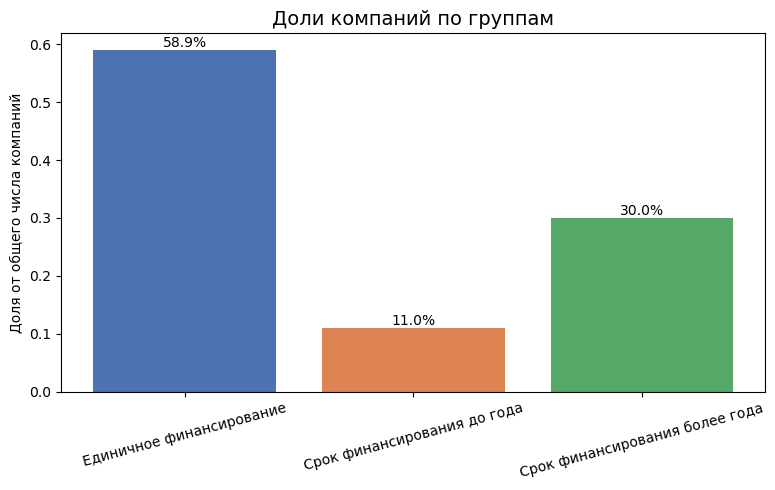

In [28]:
# Визуализируем доли по количеству компаний
plt.figure(figsize=(8, 5))
bars_count = plt.bar(
    groups_order,
    [group_shares_count.get(g, 0) for g in groups_order],
    color=[colors[g] for g in groups_order]
)

plt.ylabel('Доля от общего числа компаний')
plt.title('Доли компаний по группам', fontsize=14)
plt.xticks(rotation=15)

for bar in bars_count:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f'{height:.1%}',
        ha='center',
        va='bottom',
        fontsize=10
    )

plt.tight_layout()
plt.show()

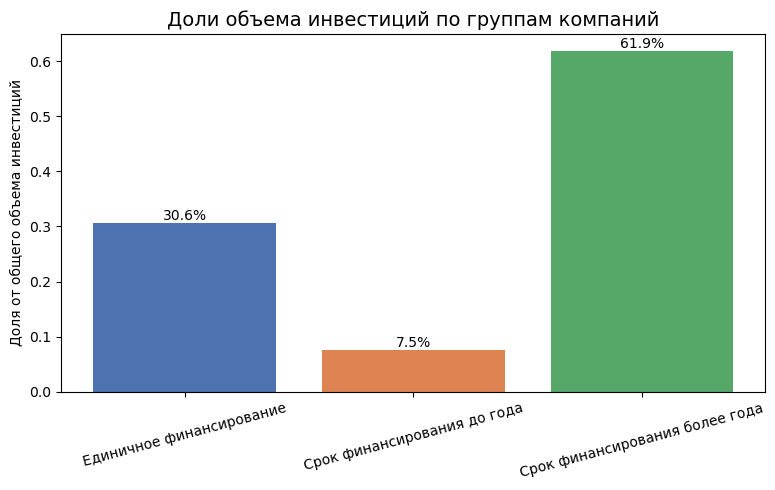

In [29]:
# Визуализируем доли по объему инвестиций
plt.figure(figsize=(8, 5))
bars = plt.bar(
    groups_order,
    [group_shares_funding.get(g, 0) for g in groups_order],
    color=[colors[g] for g in groups_order]
)

plt.ylabel('Доля от общего объема инвестиций')
plt.title('Доли объема инвестиций по группам компаний', fontsize=14)
plt.xticks(rotation=15)

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width()/2.,
        height,
        f'{height:.1%}',
        ha='center', va='bottom', fontsize=10
    )

plt.tight_layout()
plt.show()

**Выводы**

- Наиболее часто встречается единичное финансирование (59%), но по объему инвестиций оно лишь на втором месте (31%)
- Наибольший объем инвестиций у финансирования сроком более года (62%), а встречается оно реже (30%)

### Выделение средних и нишевых сегментов рынка

In [30]:
# Считаем, сколько компаний в каждом сегменте
market_counts = df_inv['market'].value_counts().reset_index()
market_counts.columns = ['market', 'count']

In [31]:
# Классифицируем сегменты
def classify_segment(count):
    if count > 120:
        return 'mass'
    elif 35 <= count <= 120:
        return 'mid'
    else:
        return 'niche'

market_counts['category'] = market_counts['count'].apply(classify_segment)

print("Распределение сегментов по категориям:")
print(market_counts['category'].value_counts())

Распределение сегментов по категориям:
category
niche    289
mid       57
mass      49
Name: count, dtype: int64


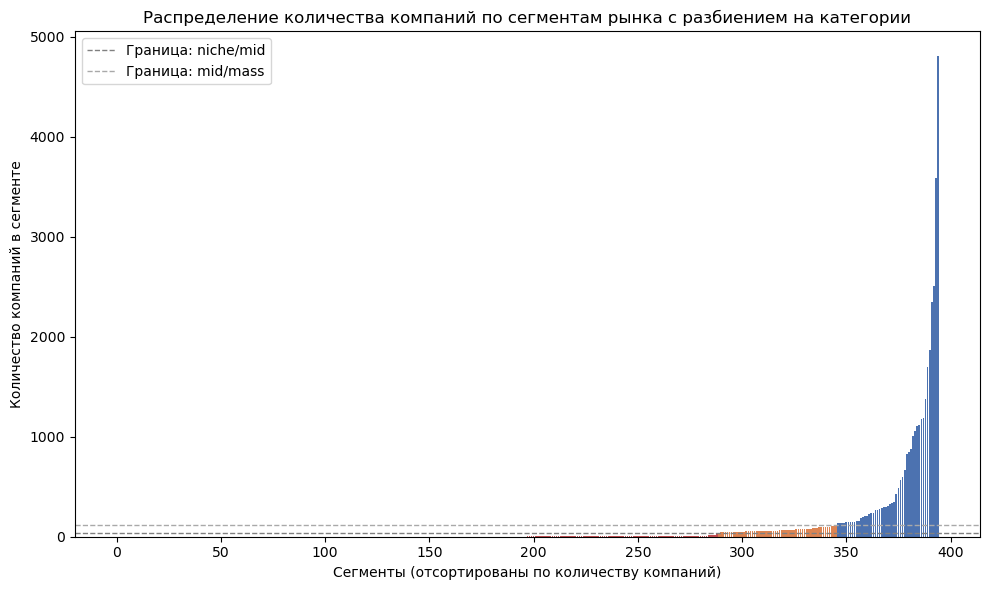

In [32]:
# Сортируем по количеству
market_counts_sorted = market_counts.sort_values('count', ascending=True)

plt.figure(figsize=(10, 6))
bars = plt.bar(
    range(len(market_counts_sorted)),
    market_counts_sorted['count'],
    color=['#4c72b0' if c == 'mass' else '#dd8452' if c == 'mid' else '#c44e52' for c in market_counts_sorted['category']]
)

# Добавим линии-разделители
plt.axhline(y=35, color='gray', linestyle='--', linewidth=1, label='Граница: niche/mid')
plt.axhline(y=120, color='darkgray', linestyle='--', linewidth=1, label='Граница: mid/mass')

plt.xlabel('Сегменты (отсортированы по количеству компаний)')
plt.ylabel('Количество компаний в сегменте')
plt.title('Распределение количества компаний по сегментам рынка с разбиением на категории')
plt.legend()
plt.tight_layout()
plt.show()

In [33]:
# Создаём словарь
market_to_category = market_counts.set_index('market')['category'].to_dict()

# Ставим заглушки на нишевые и средние сегменты
def replace_market(val):
    # Если значение неизвестно, считаем нишевым
    cat = market_to_category.get(val, 'niche')
    
    # Если массовый — оставляем оригинальное название
    if cat == 'mass':
        return val
    # Иначе (mid или niche) — возвращаем заглушку
    return cat

# Применяем к столбцу
df_inv['market'] = df_inv['market'].apply(replace_market)

# Проверяем результат
print(df_inv['market'].value_counts())

market
Software                4812
mid                     3841
Biotechnology           3590
unknown                 2503
Mobile                  2344
E-Commerce              1866
Curated Web             1693
Enterprise Software     1381
Health Care             1185
Clean Technology        1180
Games                   1117
Advertising             1107
Hardware + Software     1062
Social Media            1003
Health and Wellness      873
Education                844
niche                    830
Finance                  828
Analytics                667
Manufacturing            596
Security                 567
Semiconductors           484
Web Hosting              424
Consulting               349
Hospitality              336
Travel                   330
Fashion                  303
News                     301
Messaging                295
Search                   291
Real Estate              279
SaaS                     272
Music                    264
Internet                 241
Technol

**Выводы**

- Основная масса сегментов нишевые (289), средних и массовых сегментов примерно одинаковое кол-во (57 и 49)
- Самый массовый сегмент - программное обеспечение (4812 компаний), далее идут биотехнологии (3590) и мобильный сегмент (2344)

## Работа с выбросами и анализ

### Анализируем и помечаем выбросы в каждом из сегментов

In [34]:
# Изучаем статистические показатели столбца funding_total_usd
print('Статистические показатели столбца funding_total_usd:')
df_inv['funding_total_usd'].describe()

Статистические показатели столбца funding_total_usd:


count    4.090700e+04
mean     1.591253e+07
std      1.686788e+08
min      1.000000e+00
25%      3.500000e+05
50%      2.000000e+06
75%      1.000000e+07
max      3.007950e+10
Name: funding_total_usd, dtype: float64

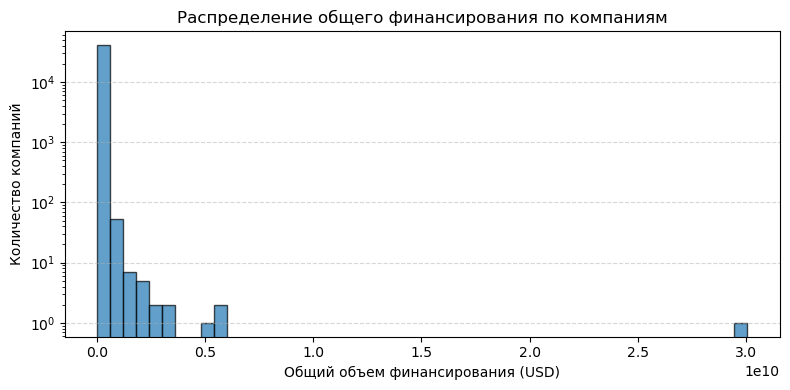

In [35]:
# Гистограмма (с логарифмической шкалой, т.к. распределение сильно скошено)
plt.figure(figsize=(8, 4))
plt.hist(df_inv['funding_total_usd'], bins=50, log=True, edgecolor='black', alpha=0.7)
plt.xlabel('Общий объем финансирования (USD)')
plt.ylabel('Количество компаний')
plt.title('Распределение общего финансирования по компаниям')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

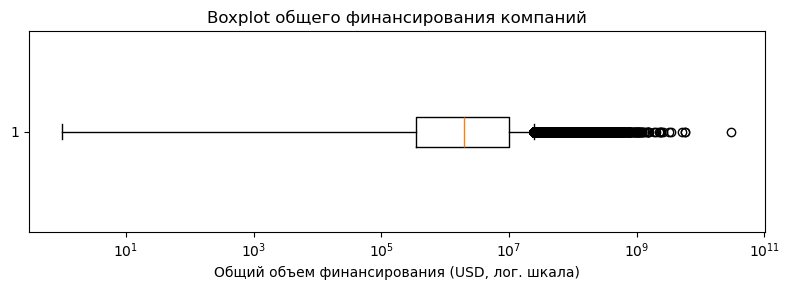

In [36]:
# Boxplot на логарифмической шкале
plt.figure(figsize=(8, 3))
plt.boxplot(df_inv['funding_total_usd'], vert=False)
ax = plt.gca()
ax.set_xscale('log')
plt.xlabel('Общий объем финансирования (USD, лог. шкала)')
plt.title('Boxplot общего финансирования компаний')
plt.tight_layout()
plt.show()

In [37]:
# Типичный диапазон значений — межквартильный промежуток (25–75 перцентиль)
q1 = df_inv['funding_total_usd'].quantile(0.25)
q3 = df_inv['funding_total_usd'].quantile(0.75)
print(f"Типичный диапазон общего финансирования (25–75 перцентиль): {q1:,.0f} – {q3:,.0f} USD")

Типичный диапазон общего финансирования (25–75 перцентиль): 350,000 – 10,000,000 USD


In [38]:
# Функция для нахождения доли компаний с аномальным объемом финансирования
def iqr_outlier_share(group):
    q1 = group.quantile(0.25)
    q3 = group.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    outliers = (group < lower) | (group > upper)
    return outliers.mean()

# Выводим топ сегментов с наибольшей долей компаний, получивших аномальное финансирование
result = (
    df_inv.groupby('market')['funding_total_usd']
    .apply(iqr_outlier_share)
    .sort_values(ascending=False)
    .head(10)
)

print(result)

market
Real Estate        0.172043
Entertainment      0.166667
Consulting         0.166189
Search             0.164948
Cloud Computing    0.164474
Photography        0.161765
SaaS               0.161765
Technology         0.159664
Video              0.159574
niche              0.159036
Name: funding_total_usd, dtype: float64


**Выводы**

- Обычным размером инвестиций можно считать значение в 1,3 млн долларов (медиана).
- Типичный диапазон общего финансирования (25–75 перцентиль): 250,000 – 5,000,000 USD.
- Можем заметить, что распределение сильно скошено вправо, и среднее значение почти в 3,5 больше медианы - это говорит о наличии очень крупных выбросов.
- Стандартное отклонение больше, чем само среднее. Это признак высокой волатильности и неоднородности данных. Дисперсия очень велика: большинство значений сконцентрировано в нижней части шкалы, а хвост распределения сильно вытянут вправо.
- Больше всего компаний с аномальным объемом финансирования в сегменте Дизайна.

### Определяем границы рассматриваемого периода, отбрасываем аномалии

In [39]:
# Проверка полноты данных за 2014 год
monthly_2014 = (
    df_inv.loc[df_inv['last_funding_at'].dt.year == 2014, 'last_funding_at']
    .dt.month.value_counts()
    .sort_index()
)
print("\nКоличество последних раундов по месяцам в 2014 году:")
print(monthly_2014)


Количество последних раундов по месяцам в 2014 году:
last_funding_at
1     1178
2      947
3     1072
4     1077
5     1036
6     1229
7     1254
8     1064
9     1135
10    1139
11     732
12      52
Name: count, dtype: int64


In [40]:
# Проверим дату последней записи в датасете
last_date = df_inv['last_funding_at'].max()
print(last_date)

2014-12-31 00:00:00


In [41]:
# Убираем компании с аномальным финансированием
def get_bounds(s):
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

lower_bound = df_inv.groupby('market')['funding_total_usd'].transform(lambda s: get_bounds(s)[0])
upper_bound = df_inv.groupby('market')['funding_total_usd'].transform(lambda s: get_bounds(s)[1])

df_inv = df_inv[
    (df_inv['funding_total_usd'] >= lower_bound) &
    (df_inv['funding_total_usd'] <= upper_bound)
]

In [42]:
# Извлекаем год из mid_funding_at
df_inv['year'] = df_inv['mid_funding_at'].dt.year

# Считаем суммарное количество раундов финансирования по годам
rounds_by_year = df_inv.groupby('year')['funding_rounds'].sum()

# Оставляем только те годы, где было зафиксировано >= 50 раундов
valid_years = rounds_by_year[rounds_by_year >= 50].index

# Фильтруем итоговый датасет
df_inv = df_inv[df_inv['year'].isin(valid_years)]

**Выводы**

- За 2014 год данные полные - хоть в декабре число записей и становится резко меньше, данные имеются вплоть до 31 декабря.
- Датасет был отфильтрован - исключены компании с аномальным объемом финансирования и не удовлетворящие заданным условиям.

### Анализ типов финансирования по объёму и популярности

In [43]:
# Список необходимых столбцов
funding_cols = [
    'seed', 'venture', 'equity_crowdfunding', 'undisclosed',
    'convertible_note', 'debt_financing', 'angel', 'grant',
    'private_equity', 'post_ipo_equity', 'post_ipo_debt',
    'secondary_market', 'product_crowdfunding'
]

# Суммарные объемы привлеченных средств по типам финансирования
total_by_type = df_inv[funding_cols].sum().sort_values(ascending=False)

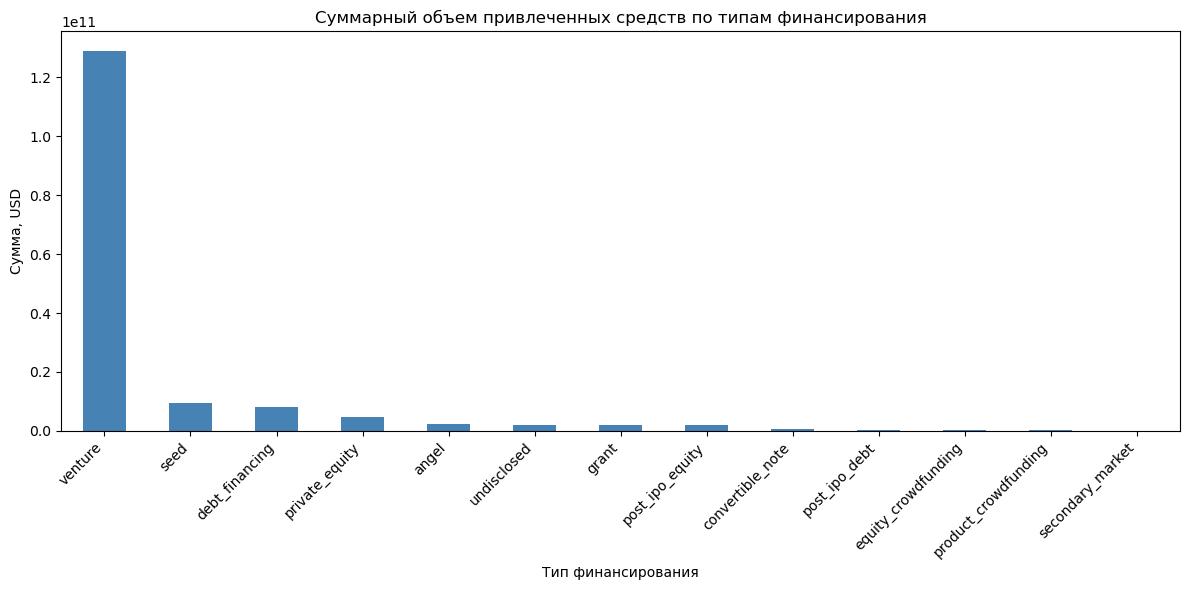

In [44]:
# Визуализируем суммарные объемы привлеченных средств по типам финансирования
plt.figure(figsize=(12, 6))
total_by_type.plot(kind='bar', color='steelblue')
plt.title('Суммарный объем привлеченных средств по типам финансирования')
plt.xlabel('Тип финансирования')
plt.ylabel('Сумма, USD')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [45]:
# Считаем количество ненулевых и непустых значений в каждом столбце
popularity_by_type = (df_inv[funding_cols] > 0).sum().sort_values(ascending=False)

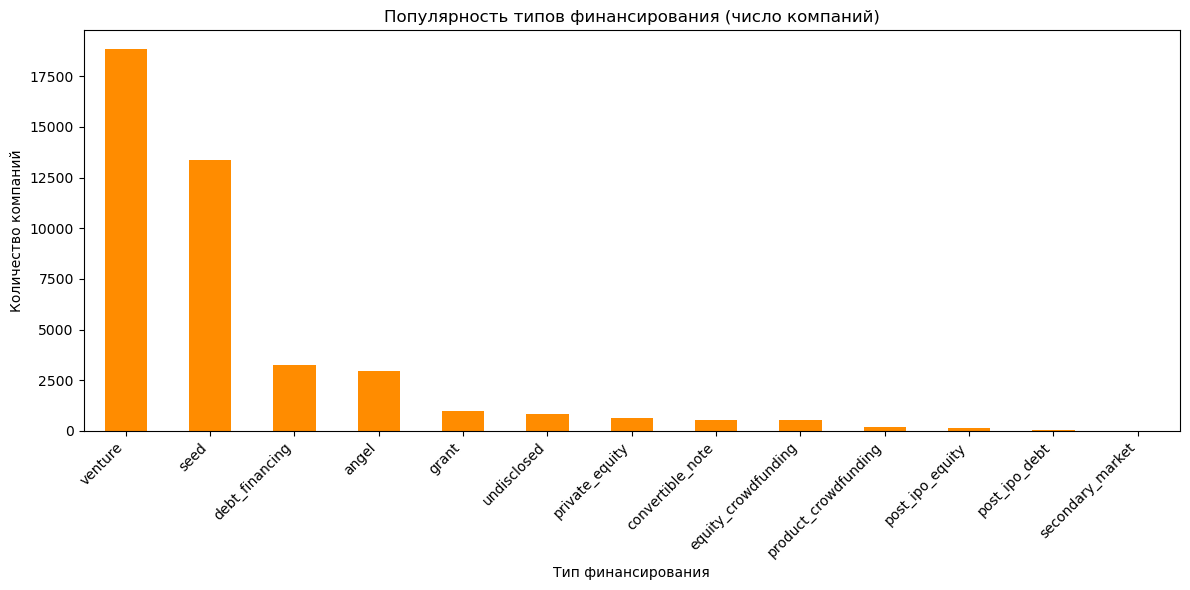

In [46]:
# Визуализируем популярность разных типов финансирования
plt.figure(figsize=(12, 6))
popularity_by_type.plot(kind='bar', color='darkorange')
plt.title('Популярность типов финансирования (число компаний)')
plt.xlabel('Тип финансирования')
plt.ylabel('Количество компаний')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [47]:
# Суммарные объемы возвратов по типам финансирования
total_returns_by_type = df_ret[funding_cols].sum().sort_values(ascending=False)

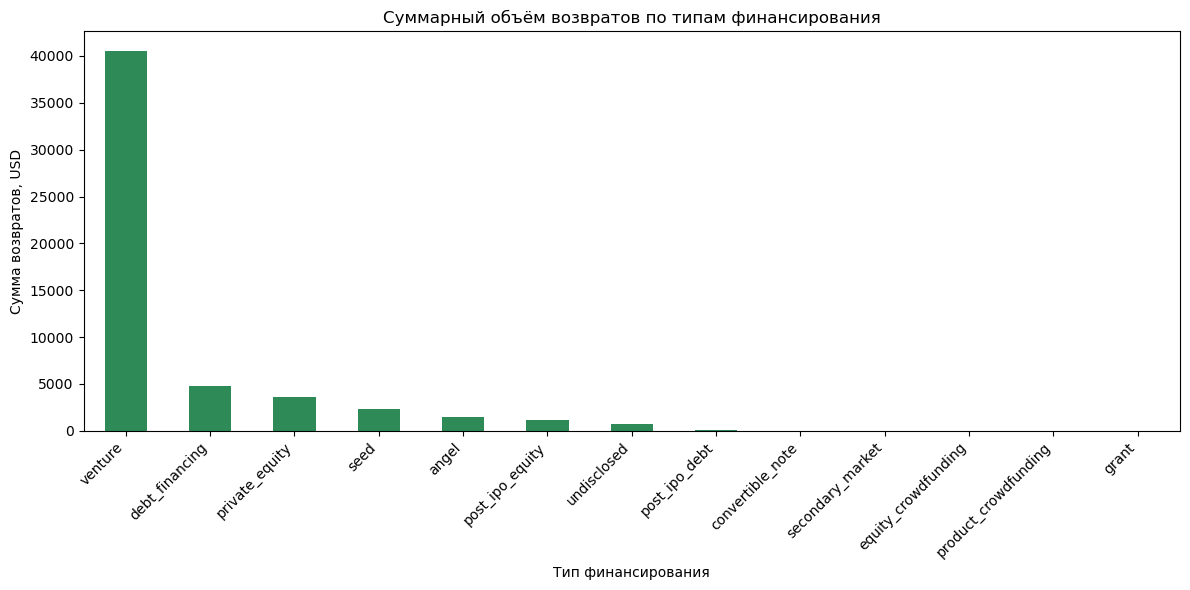

In [48]:
# Визуализируем суммарные объемы возвратов по типам финансирования
plt.figure(figsize=(12, 6))
total_returns_by_type.plot(kind='bar', color='seagreen')
plt.title('Суммарный объём возвратов по типам финансирования')
plt.xlabel('Тип финансирования')
plt.ylabel('Сумма возвратов, USD')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [49]:
# Объединяем данные по суммарному объему и популярности разных типов финансирования
comparison = pd.DataFrame({
    'total_amount': total_by_type,
    'popularity': popularity_by_type
})

# Ранжируем по каждому показателю (1 = самый большой/популярный)
comparison['amount_rank'] = comparison['total_amount'].rank(ascending=False)
comparison['popularity_rank'] = comparison['popularity'].rank(ascending=False)

# Разница рангов: положительная — тип редкий, но с большими суммами
# отрицательная — тип частый, но с небольшими суммами
comparison['rank_diff'] = comparison['popularity_rank'] - comparison['amount_rank']

comparison_sorted = comparison.sort_values('rank_diff', ascending=False)
print(comparison_sorted[['amount_rank', 'popularity_rank', 'rank_diff']])

                      amount_rank  popularity_rank  rank_diff
post_ipo_equity               8.0             11.0        3.0
private_equity                4.0              7.0        3.0
post_ipo_debt                10.0             12.0        2.0
debt_financing                3.0              3.0        0.0
secondary_market             13.0             13.0        0.0
seed                          2.0              2.0        0.0
undisclosed                   6.0              6.0        0.0
venture                       1.0              1.0        0.0
angel                         5.0              4.0       -1.0
convertible_note              9.0              8.0       -1.0
equity_crowdfunding          11.0              9.0       -2.0
grant                         7.0              5.0       -2.0
product_crowdfunding         12.0             10.0       -2.0


**Выводы**

- Венчурные инвестиции лидируют - у них самые большие объемы по инвестициям и возвратам и ими чаще всего пользуются компании.
- Посевные инвестиции на втором месте - они сопоставимы по популярности с венчурными, но сильно отстают по объемам.
- Редко встречаются, но имеют значительные объемы следующие типы инвестиций: прямые частные инвестиции, финансирование после IPO и долговое финансирование после IPO.
- Встречаются часто, но имеют низкие объемы следующие типы инвестиций: инвестиции, привлеченные через долевой и продуктовый краудфандинг, полученные гранты.

## Анализ динамики

### Динамика предоставления финансирования по годам

In [50]:
# Средний объем одного раунда финансирования для каждой компании
df_inv['avg_round_size'] = df_inv['funding_total_usd'] / df_inv['funding_rounds']

# Типичный (медианный) размер раунда по годам
yearly_avg_round = df_inv.groupby('year')['avg_round_size'].median()

# Суммарное количество раундов по годам
yearly_rounds = df_inv.groupby('year')['funding_rounds'].sum()

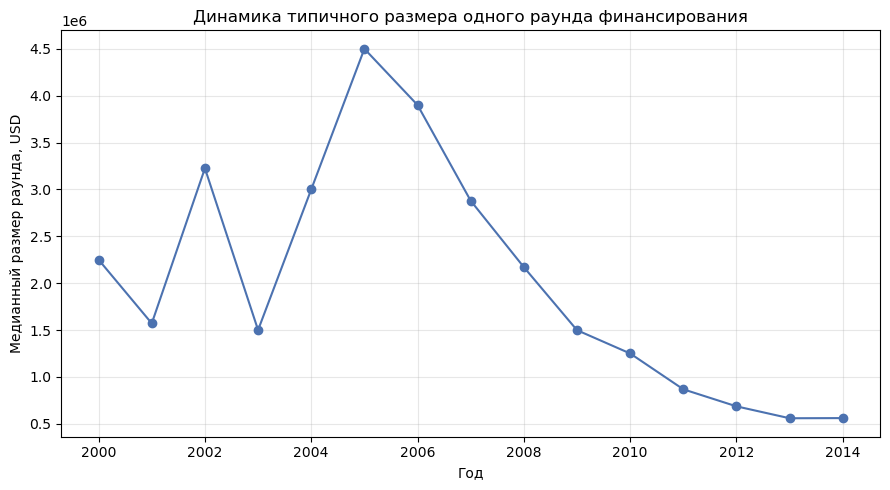

In [51]:
# Визуализируем динамику типичного размера средств
plt.figure(figsize=(9, 5))
plt.plot(yearly_avg_round.index, yearly_avg_round.values, marker='o', color='#4c72b0')
plt.xlabel('Год')
plt.ylabel('Медианный размер раунда, USD')
plt.title('Динамика типичного размера одного раунда финансирования')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

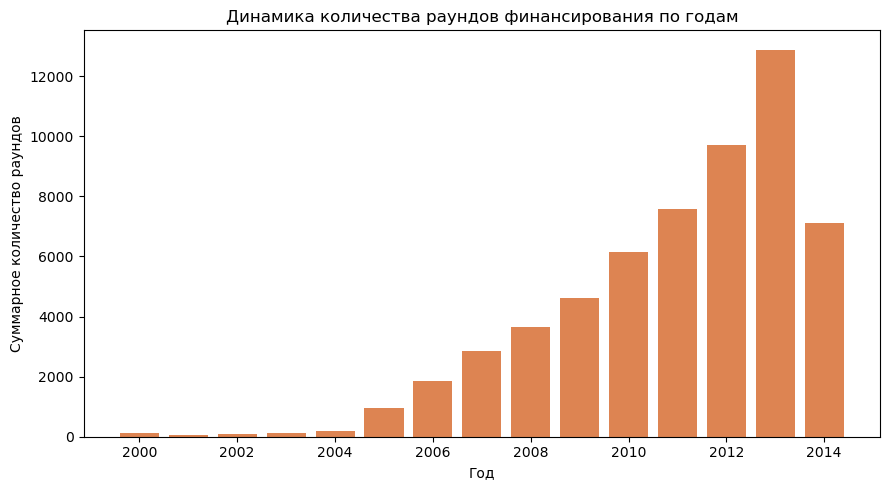

In [52]:
# Визуализируем динамику общего количества раундов за каждый год
plt.figure(figsize=(9, 5))
plt.bar(yearly_rounds.index, yearly_rounds.values, color='#dd8452')
plt.xlabel('Год')
plt.ylabel('Суммарное количество раундов')
plt.title('Динамика количества раундов финансирования по годам')
plt.tight_layout()
plt.show()

In [53]:
# Сравнение 2013 и 2014 годов по обоим показателям
for y in [2013, 2014]:
    if y in yearly_avg_round.index:
        print(f"{y}: медианный размер раунда = {yearly_avg_round[y]:,.0f} USD, "
              f"суммарно раундов = {yearly_rounds[y]}")
    else:
        print(f"{y}: данных нет в отфильтрованном датасете")

2013: медианный размер раунда = 559,000 USD, суммарно раундов = 12880.0
2014: медианный размер раунда = 560,625 USD, суммарно раундов = 7122.0


**Выводы**

- Максимальным типичный размер средств, собранных в рамках одного раунда, был в 2005 году.
- В 2014 году, по сравнению с 2013 годом, типичный размер средств остался на том же уровне, а количество раундов снизилось почти в 2 раза.

### Динамика размера общего финансирования по массовым сегментам рынка для растущих в 2014 году сегментов

In [54]:
# Сводная таблица: суммарное финансирование по годам и сегментам рынка
segment_year_funding = df_inv.pivot_table(
    index='year', columns='market', values='funding_total_usd', aggfunc='sum'
)

# Оставляем только массовые сегменты — исключаем заглушки mid и niche
mass_segments = [c for c in segment_year_funding.columns if c not in ('mid', 'niche')]
segment_year_funding = segment_year_funding[mass_segments]

# Ищем сегменты, показавшие рост суммарного финансирования в 2014 году относительно 2013
if 2013 in segment_year_funding.index and 2014 in segment_year_funding.index:
    growth_2014 = segment_year_funding.loc[2014] - segment_year_funding.loc[2013]
    growing_segments = growth_2014[growth_2014 > 0].dropna().index.tolist()
else:
    growth_2014 = pd.Series(dtype=float)
    growing_segments = []

print("Массовые сегменты, показавшие рост финансирования в 2014 году:")
print(growing_segments)

Массовые сегменты, показавшие рост финансирования в 2014 году:
['Apps', 'Big Data', 'Design', 'Internet', 'Manufacturing', 'Medical', 'Real Estate', 'SaaS', 'Startups', 'Technology', 'unknown']


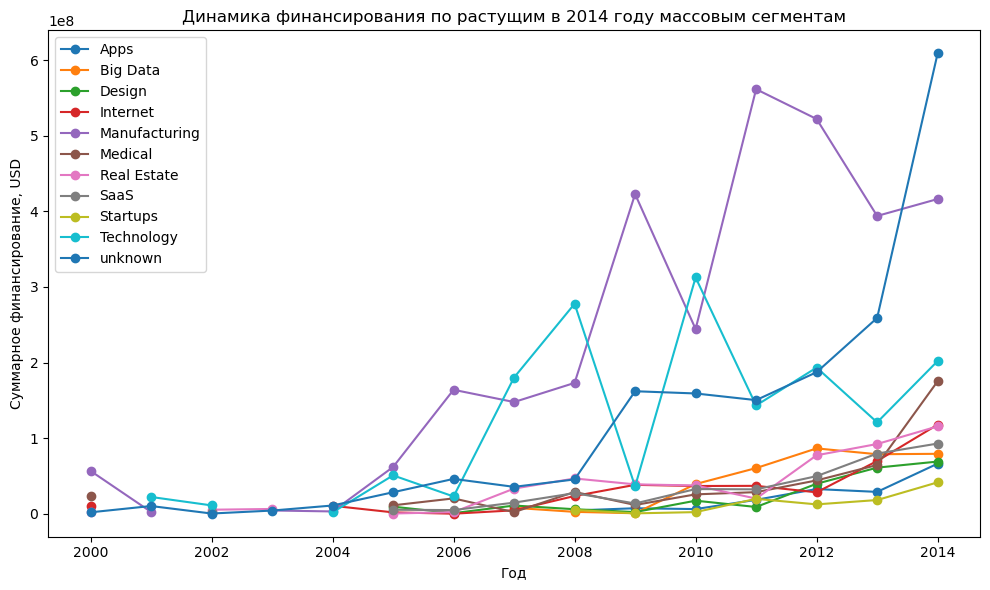

In [55]:
# Динамика суммарного финансирования по растущим массовым сегментам
plt.figure(figsize=(10, 6))
for seg in growing_segments:
    plt.plot(segment_year_funding.index, segment_year_funding[seg], marker='o', label=seg)

plt.xlabel('Год')
plt.ylabel('Суммарное финансирование, USD')
plt.title('Динамика финансирования по растущим в 2014 году массовым сегментам')
plt.legend()
plt.tight_layout()
plt.show()

**Выводы**

- Наиболее быстрый и уверенный рост показывают компании без указанного сегмента и компании из сегмента производства.
- Компании из сегмента технологий также показывают быстрый, но менее стабильный рост.
- Компании из сегмента медицины показали значительный рост в последние годы.

### Годовая динамика доли возвращённых средств по типам финансирования

In [56]:
# Для каждого года и типа финансирования считаем, какую долю от выданных средств составили возвраты
returns_share = pd.DataFrame(index=df_ret.index)

for t in funding_cols:
    provided = df_inv.groupby('year')[t].sum()
    returns_share[t] = (df_ret[t] * 1e6) / (provided.reindex(df_ret.index) + 1e-60)

# Аномально большие доли возврата (более чем двукратные) заменяем на пропуски
returns_share = returns_share.mask(returns_share > 2)

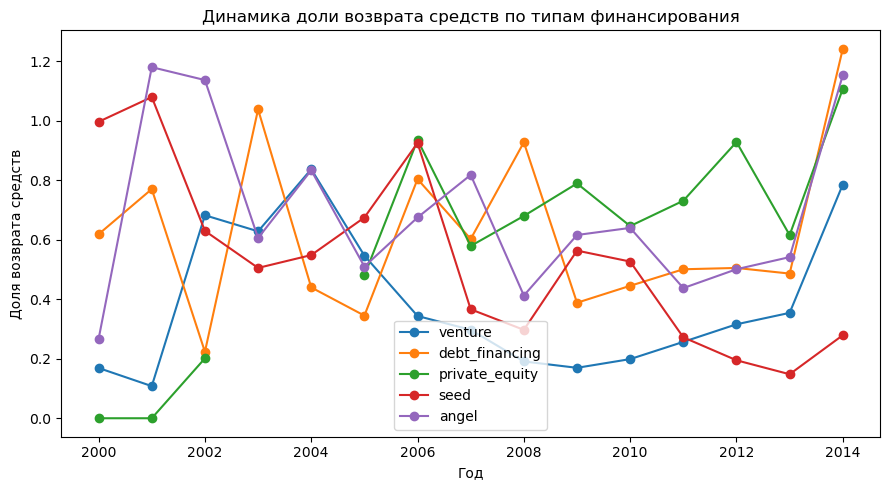

In [57]:
# Динамика нормированного возврата средств для ключевых типов финансирования
types_to_plot = ['venture', 'debt_financing', 'private_equity', 'seed', 'angel']

plt.figure(figsize=(9, 5))
for t in types_to_plot:
    plt.plot(returns_share.index, returns_share[t], marker='o', label=t)

plt.xlabel('Год')
plt.ylabel('Доля возврата средств')
plt.title('Динамика доли возврата средств по типам финансирования')
plt.legend()
plt.tight_layout()
plt.show()

**Выводы**

- Наиболее устойчивый рост доли возврата средств наблюдается у прямых частных инвестиций.
- Более скачкообразный рост заметен у долгового, венчурного и ангельского финансирования.
- Посевное финансирование показывает снижение показателя.

## Итоговый вывод и рекомендации

### Рекомендации заказчику

**В какую отрасль стоит инвестировать.**
Среди массовых сегментов рынка, показавших рост финансирования в 2014 году относительно 2013-го, наиболее убедительно выглядит **медицина** — этот сегмент демонстрирует значительный и устойчивый рост в последние годы анализируемого периода, в отличие от технологического сегмента, чей рост был быстрым, но нестабильным (скачкообразным). Сегмент **производства** также показал уверенный рост, поэтому его можно рассматривать как дополнительный, более консервативный вариант диверсификации. Таким образом, приоритетная рекомендация — **направить инвестиции в медицинский сегмент**, с возможным дополнением в виде сегмента производства для снижения рисков.

**Какой тип финансирования будет наиболее уместен.**
Венчурное финансирование (`venture`) — безусловный лидер рынка: у него наибольший суммарный объем привлеченных средств, наибольший объём возвратов и максимальная популярность среди компаний. Это делает венчурные инвестиции наиболее естественным и проверенным инструментом для входа на рынок стартапов. При этом стоит учитывать, что доля возврата средств по венчурному финансированию растёт скачкообразно, то есть с колебаниями от года к году. Наиболее стабильный и устойчивый рост доли возврата средств показывают прямые частные инвестиции (`private_equity`) — этот тип реже встречается, но характеризуется крупными объемами и предсказуемой динамикой возвратов, поэтому он может быть рассмотрен как дополнение к венчурному финансированию для более консервативной части портфеля. От посевного финансирования (`seed`), несмотря на его популярность, в 2015 году стоит воздержаться — доля возврата по нему в последние годы снижается.

**Итог:** заказчику рекомендуется рассмотреть венчурное финансирование стартапов медицинского сегмента как основную стратегию, с возможным добавлением сделок в формате прямых частных инвестиций для повышения устойчивости портфеля и дополнительными вложениями в производственный сегмент.

### Итоги проекта

**Выполненные шаги:**
1. Загружены и изучены два датасета — `cb_investments` (сведения о компаниях и их финансировании) и `cb_returns` (статистика по возвратам средств по годам и типам финансирования).
2. Проведена предобработка данных: очищены названия столбцов, приведены к нужным типам данные о суммах и датах, удалены полные дубликаты и полностью пустые строки, восстановлена часть пропусков в дате `mid_funding_at`, датасет `cb_returns` проиндексирован по году.
3. Выполнен инжиниринг признаков: компании разделены на группы по длительности периода финансирования (единичное финансирование, финансирование до года и более года), сегменты рынка (`market`) классифицированы на массовые, средние и нишевые.
4. Проведён анализ выбросов по объему финансирования методом IQR — как в целом по датасету, так и в разрезе рыночных сегментов; выбросы отброшены, определены и обоснованы границы рассматриваемого периода.
5. Проанализирована структура типов финансирования: сопоставлены суммарные объемы, популярность (частота использования) и объемы возвратов по каждому типу.
6. Исследована динамика рынка по годам: типичный размер раунда, суммарное количество раундов, рост отдельных массовых сегментов в 2014 году, а также годовая динамика доли возврата средств по ключевым типам финансирования.

**Основные выводы:**
- Большинство компаний привлекают финансирование в рамках единичного раунда, но по объему средств лидируют компании с длительным (более года) циклом финансирования — то есть крупные суммы чаще привлекаются постепенно, а не одномоментно.
- Рынок сильно неоднороден: распределение объемов финансирования сильно скошено вправо, что типично для венчурного рынка, где основная масса сделок небольшая, а на итоговый объем сильно влияют единичные крупные раунды.
- Софт, биотехнологии и мобильный сегмент — самые массовые по числу компаний сегменты рынка, однако наиболее динамично растущим в 2014 году оказался сегмент медицины.
- Венчурное и посевное финансирование — самые популярные типы, но именно венчурное лидирует и по суммарным объемам, и по возвратам. Прямые частные инвестиции, финансирование и долговое финансирование после IPO — редкие, но крупные по объему типы сделок. Краудфандинг и гранты — частые, но небольшие по объему.
- Доля возврата средств растет наиболее стабильно у прямых частных инвестиций, более волатильно — у венчурного, долгового и ангельского финансирования, и снижается — у посевного.
- В 2014 году, по сравнению с 2013-м, типичный размер раунда остался на прежнем уровне, но суммарное количество раундов сократилось почти вдвое — это может говорить как о замедлении рынка, так и о неполноте декабрьских данных за 2014 год, что стоит учитывать при интерпретации.

**Согласованность выводов.**
В целом выводы разных разделов проекта хорошо согласуются друг с другом: венчурное финансирование стабильно занимает лидирующие позиции и по объему, и по популярности, и по возвратам, что делает вывод о его приоритетности достаточно надежным. Вывод о росте медицинского сегмента также подтверждается отдельно на графике динамики по массовым сегментам. Вместе с тем часть выводов требует осторожной интерпретации: сокращение числа раундов в 2014 году может быть связано не с реальным спадом рынка, а с неполнотой данных за последний месяц года — это ограничивает уверенность в выводах о состоянии рынка непосредственно перед 2015 годом. Также стоит учитывать, что классификация рыночных сегментов на массовые/средние/нишевые и группировка по срокам финансирования основаны на выбранных заранее пороговых значениях, которые в определённой степени условны и при их изменении результаты анализа отдельных сегментов могут несколько измениться. В остальном общая картина рынка — доминирование венчурного капитала, неоднородность распределения объемов финансирования и наличие растущих отраслевых сегментов — выглядит целостной и не содержит выводов, противоречащих друг другу.